# 07 · Zweite Domäne: Stromlast

Gleiches Experiment wie 06, aber auf stündlicher **Netzlast** (MW) von vier Ländern statt auf Volatilität.
Frage: Sind die Foundation Models auch hier redundant, oder hilft das Kombinieren in einer anderen Domäne?

- **Daten:** Last (Load) von Deutschland, Frankreich, Italien, Spanien über die öffentliche Energy-Charts-API (Fraunhofer ISE, CC BY 4.0), 15 min → stündlich
- **Experten:** dieselben 4 FMs wie in 06. Statt HAR/GARCH die klassischen Lastmodelle Seasonal Naive (gleiche Stunde letzte Woche) und eine saisonale Regression
- **Gate:** wie in 06, nur Zeitreihe (24 h) + Disagree
- **Loss:** statt QLIKE (für Varianzen gedacht) quadratischer Fehler relativ zum Lastniveau + Pinball. Bewertet wird mit MAPE

**Kaggle:** rechts *Accelerator = GPU T4*, *Internet = On*, dann *Run All* oder *Save Version → Save & Run All*. Lokal läuft es genauso, die erste Zelle erkennt Kaggle selbst.

In [1]:
# Setup: nur auf Kaggle Repo klonen und Pakete installieren. Lokal: Notebook aus src/ starten.
import os, subprocess, sys
from pathlib import Path

if Path("/kaggle/working").exists():
    repo = Path("/kaggle/working/repo")
    if not repo.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/ihringerlinus/Learning_to_Forecast_Time-Series_with_Multiple_Experts.git",
                        str(repo)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chronos-forecasting", "timesfm[torch]",
                    "tirex-ts", "granite-tsfm", "pyarrow"], check=True)
    os.chdir(repo / "src")
elif not Path("pipeline").exists() and Path("src/pipeline").exists():
    os.chdir("src")                     # lokal aus dem Repo-Ordner gestartet (z. B. PyCharm)
print("Arbeitsordner:", Path.cwd())

Arbeitsordner: /Users/sebastianjung/Documents/HSG/HS 26/BP/Learning_to_Forecast_Time-Series_with_Multiple_Experts/src


In [2]:
import json, time
from functools import partial
from statistics import NormalDist

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import torch
from tqdm.auto import tqdm

from pipeline import common as C, experts as ex, features as F, combine as cb

DATASET = "strom_1h"
COUNTRIES = ["de", "fr", "it", "es"]
FIRST_DAY, LAST_DAY = "2024-07-01", "2026-02-28"      # nichts ab März 2026: Testperiode bleibt zu
CHUNK_MONTHS = 6                                       # Monate pro API-Anfrage (bei Fehlern kleiner wählen)

C.ORIGIN_START = "2025-01-01"
EVAL_START, EVAL_END, TUNE_DAYS = "2025-11-01", "2026-02-28", 90
if torch.cuda.is_available():
    C.FM_BATCH = 512

FMS = ["Chronos-2-full", "TimesFM-2.5", "TiRex", "FlowState"]
CLASSIC = ["SNaive", "SeasReg"]
MODELS = ["RW"] + CLASSIC + FMS
POOLS = {
    "2 FMs (alt)": ["Chronos-2-full", "TimesFM-2.5"],
    "4 FMs": FMS,
    "4 FMs + klassisch": FMS + CLASSIC,
}
RAW_LAGS = 24
LAMBDAS = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
ONLY_CACHE = not Path("/kaggle/working").exists()     # lokal: keine Expertenprognosen neu rechnen, nur Cache nutzen

DATA_DIR = (Path("data") / DATASET).resolve()
RAW_DIR = (Path("data") / "raw" / "energy_charts").resolve()
FC_DIR = (Path("results") / "forecasts" / DATASET).resolve()
for d in (DATA_DIR, RAW_DIR, FC_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Gerät:", ex._device(), "| nur Cache:", ONLY_CACHE)
print("Cache:", len(list(DATA_DIR.glob("*.parquet"))), "Länder,", len(list(FC_DIR.glob("*__*.parquet"))), "Prognosedateien,",
      "Gate-Ergebnisse" if (FC_DIR.parent / "07_res.parquet").exists() else "keine Gate-Ergebnisse")

Gerät: cpu | nur Cache: True
Cache: 4 Länder, 28 Prognosedateien, Gate-Ergebnisse


## 1 · Daten

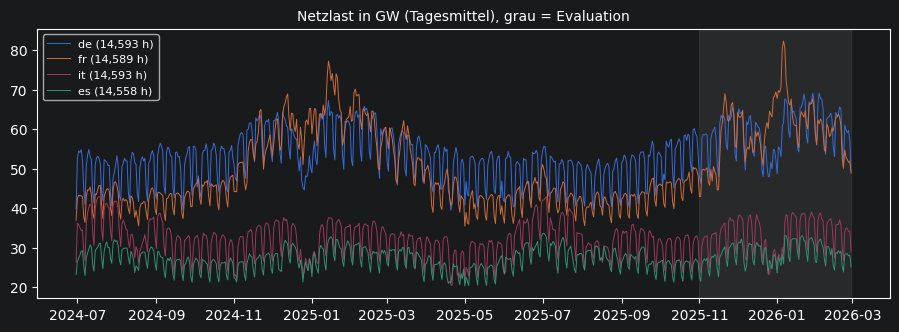

In [3]:
API = "https://api.energy-charts.info/public_power"


def fetch(country, start, end):
    # eine API-Anfrage mit Cache. Die API erlaubt ca. 2 Anfragen pro Minute.
    path = RAW_DIR / f"{country}_{start}_{end}.json"
    if path.exists():
        return json.loads(path.read_text())
    while True:
        r = requests.get(API, params={"country": country, "start": start, "end": end}, timeout=180)
        if r.status_code == 429:
            wait = int(r.headers.get("Retry-After", 60))
            print(f"  Rate-Limit, warte {wait}s")
            time.sleep(wait)
            continue
        r.raise_for_status()
        break
    path.write_text(r.text)
    time.sleep(31)
    return r.json()


def hourly_load(country):
    path = DATA_DIR / f"{country}_daily.parquet"                   # Name wie in 01, Spalte rv = Last
    if path.exists():
        return pd.read_parquet(path)
    parts = []
    for a in pd.date_range(FIRST_DAY, LAST_DAY, freq=f"{CHUNK_MONTHS}MS"):
        b = min(a + pd.DateOffset(months=CHUNK_MONTHS) - pd.Timedelta(days=1), pd.Timestamp(LAST_DAY))
        js = fetch(country, a.strftime("%Y-%m-%d"), b.strftime("%Y-%m-%d"))
        load = next((p["data"] for p in js["production_types"] if p["name"] == "Load"), None)
        if load is None:
            raise ValueError(f"{country}: keine Reihe 'Load', vorhanden: {[p['name'] for p in js['production_types']]}")
        parts.append(pd.Series(np.array(load, dtype=float), index=pd.to_datetime(js["unix_seconds"], unit="s")))
        print(f"{country}: {a.date()} bis {b.date()} geladen")
    s = pd.concat(parts).sort_index()
    h = s[~s.index.duplicated()].resample("1h").mean().dropna()
    h = h[h > 0]
    d = pd.DataFrame({"rv": h, "ret": np.log(h).diff().fillna(0.0)}).rename_axis("date")
    d.to_parquet(path)
    return d


daily = {c: hourly_load(c) for c in COUNTRIES}
(Path("data") / f"{DATASET}.json").write_text(json.dumps(
    {"name": DATASET, "sids": COUNTRIES, "daily_dir": str(DATA_DIR), "forecast_dir": str(FC_DIR),
     "test_start": "2026-03-01", "info": {"source": "energy-charts.info public_power, Load"}}, indent=2))

fig, ax = plt.subplots(figsize=(11, 3.5))
for c, d in daily.items():
    ax.plot(d["rv"].resample("D").mean() / 1000, lw=0.7, label=f"{c} ({len(d):,} h)")
ax.axvspan(pd.Timestamp(EVAL_START), pd.Timestamp(EVAL_END), color="grey", alpha=0.15)
ax.set_title("Netzlast in GW (Tagesmittel), grau = Evaluation", fontsize=10)
ax.legend(fontsize=8)
plt.show()

## 2 · Experten

- **SNaive:** gleiche Stunde vor einer Woche, Unsicherheit aus den Fehlern der letzten 90 Tage
- **SeasReg:** Regression der log-Last auf den letzten Wert, die gleiche Stunde gestern und letzte Woche und das 24-h-Mittel, je Horizont und rollierend geschätzt (die Last-Version von HAR)
- **FMs:** wie in 06 zero-shot auf der log-Last, Kontext 1024 h

In [4]:
def from_log9(logq9):
    # (n, H, 9) Log-Quantile 0.1..0.9 -> Mittelwert und 21 Quantile, wie TimesFM in experts.py
    logq9 = np.sort(np.asarray(logq9, float)[:, [h - 1 for h in C.HORIZONS], :], axis=-1)
    q = np.sort(np.exp(ex.expand_quantiles(logq9)), axis=-1)
    return C.mean_from_quantiles(q), q


class SeasonalNaive(ex.Expert):
    name = "SNaive"

    def forecast(self, s, origins):
        L = s.logrv
        mean, q = self._alloc(len(origins))
        for i, t in enumerate(origins):
            for j, h in enumerate(C.HORIZONS):
                u = np.arange(max(168, t - C.EST_WINDOW + 1), t - h + 1)     # Ziele u+h schon bekannt
                resid = L[u + h] - L[u + h - 168]
                mean[i, j], q[i, j] = C.dist_from_log_resid(L[t + h - 168], resid)
        return mean, q


class SeasonalRegression(ex.Expert):
    name = "SeasReg"

    def forecast(self, s, origins):
        L = s.logrv
        m24 = pd.Series(L).rolling(24).mean().to_numpy()
        mean, q = self._alloc(len(origins))
        for j, h in enumerate(C.HORIZONS):
            X = lambda u: np.column_stack([np.ones(len(u)), L[u], L[u + h - 24], L[u + h - 168], m24[u]])
            for i, t in enumerate(origins):
                u = np.arange(max(168, t - C.EST_WINDOW + 1), t - h + 1)
                Xu = X(u)
                beta, *_ = np.linalg.lstsq(Xu, L[u + h], rcond=None)
                mean[i, j], q[i, j] = C.dist_from_log_resid((X(np.array([t])) @ beta)[0], L[u + h] - Xu @ beta)
        return mean, q


class TiRex(ex.Expert):
    """NX-AI, Mai 2025, xLSTM (rekurrent)."""
    name = "TiRex"

    def __init__(self, chunk=1024):
        from tirex import load_model
        self.chunk = chunk
        self.model = load_model("NX-AI/TiRex", backend="torch", device=ex._device())

    def forecast(self, s, origins):
        ctx = np.stack(ex.contexts_for(s, origins))
        parts = []
        for k in tqdm(range(0, len(ctx), self.chunk), desc=f"TiRex {s.sid}", leave=False):
            q, _ = self.model.forecast(context=ctx[k:k + self.chunk], prediction_length=max(C.HORIZONS),
                                       output_type="numpy", batch_size=256)
            parts.append(q)
        return from_log9(np.concatenate(parts))


class FlowState(ex.Expert):
    """IBM, 2025, State-Space-Modell. Version r1. scale_factor 1.0 = Stundendaten mit Tageszyklus.
    batch 64 passt auf eine T4, lokal auf der CPU braucht das ca. 5 GB RAM."""
    name = "FlowState"

    def __init__(self, batch=64, scale_factor=1.0):
        from tsfm_public import FlowStateForPrediction
        self.batch, self.scale = batch, scale_factor
        self.model = (FlowStateForPrediction.from_pretrained("ibm-granite/granite-timeseries-flowstate-r1")
                      .to(ex._device()).eval())

    def forecast(self, s, origins):
        ctx = np.stack(ex.contexts_for(s, origins))
        parts = []
        for k in tqdm(range(0, len(ctx), self.batch), desc=f"FlowState {s.sid}", leave=False):
            x = torch.from_numpy(ctx[k:k + self.batch])[:, :, None].to(ex._device())
            with torch.no_grad():
                out = self.model(x, scale_factor=self.scale, prediction_length=max(C.HORIZONS), batch_first=True)
            parts.append(out.quantile_outputs[..., 0].cpu().numpy().transpose(0, 2, 1))
        return from_log9(np.concatenate(parts))


EXPERTS = {**ex.EXPERTS, "SNaive": SeasonalNaive, "SeasReg": SeasonalRegression, "TiRex": TiRex, "FlowState": FlowState}
series = {c: ex.RVSeries(c, daily[c]) for c in COUNTRIES}
print({c: len(x.origins) for c, x in series.items()}, "Ursprünge")

for m in MODELS:
    todo = [c for c in COUNTRIES if not (FC_DIR / f"{c}__{m}.parquet").exists()]
    if not todo:
        print(f"{m:>15} | gecacht")
        continue
    if ONLY_CACHE:
        print(f"{m:>15} | fehlt im Cache für {todo}, übersprungen (ONLY_CACHE = False zum Rechnen)")
        continue
    try:
        expert = EXPERTS[m]()
    except ImportError as e:
        print(f"{m:>15} | übersprungen, Paket fehlt ({e.name})")
        continue
    for c in todo:
        t0, s = time.time(), series[c]
        mean, q = expert.forecast(s, s.origins)
        ex.forecast_frame(m, s, s.origins, mean, q).to_parquet(FC_DIR / f"{c}__{m}.parquet")
        print(f"{m:>15} | {c}: {time.time() - t0:.0f}s")
    del expert
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

{'de': 10151, 'fr': 10147, 'it': 10151, 'es': 10116} Ursprünge
             RW | gecacht
         SNaive | gecacht
        SeasReg | gecacht
 Chronos-2-full | gecacht
    TimesFM-2.5 | gecacht
          TiRex | gecacht
      FlowState | gecacht


## 3 · Wie gut sind die einzelnen Experten? (Evaluation Nov 25 – Feb 26)

In [5]:
fc_all = pd.concat([pd.read_parquet(p) for p in sorted(FC_DIR.glob("*__*.parquet"))], ignore_index=True)
MODELS = [m for m in MODELS if m in set(fc_all["model"])]
POOLS = {k: [m for m in v if m in MODELS] for k, v in POOLS.items()}
print("Pools:", POOLS)

ev = fc_all[(fc_all["target_date"] >= EVAL_START) & (fc_all["target_date"] < pd.Timestamp(EVAL_END) + pd.Timedelta(days=1))].copy()
ev["ape"] = 100 * np.abs(ev["y"] - ev["mean"]) / ev["y"]
ev["logerr"] = np.log(ev["y"] / ev["mean"])

print("MAPE in % (kleiner = besser)")
display(ev.pivot_table(index=["h", "sid"], columns="model", values="ape")[MODELS].round(2))

for h in C.HORIZONS:
    E = ev[ev["h"] == h].pivot_table(index=["sid", "origin"], columns="model", values="logerr")
    print(f"h={h}: Korrelation der Log-Fehler")
    display(E[[m for m in MODELS if m != "RW"]].corr().round(2))

Pools: {'2 FMs (alt)': ['Chronos-2-full', 'TimesFM-2.5'], '4 FMs': ['Chronos-2-full', 'TimesFM-2.5', 'TiRex', 'FlowState'], '4 FMs + klassisch': ['Chronos-2-full', 'TimesFM-2.5', 'TiRex', 'FlowState', 'SNaive', 'SeasReg']}
MAPE in % (kleiner = besser)


model     RW  SNaive  SeasReg  Chronos-2-full  TimesFM-2.5  TiRex  FlowState
h  sid                                                                      
1  de   3.34    5.75     2.92            0.85         0.86   0.70       0.70
   es   4.26    5.18     3.43            1.00         0.95   0.80       0.76
   fr   2.95    9.96     2.98            0.79         0.90   0.66       0.75
   it   5.15    6.90     4.33            1.14         1.10   0.92       0.91
24 de   6.88    5.87     4.98            2.95         3.89   3.89       3.35
   es   7.44    5.21     4.71            2.98         3.96   4.12       3.45
   fr   5.00   10.03     5.84            3.70         4.49   3.69       3.66
   it   9.29    6.94     6.40            3.57         4.87   4.16       4.03

h=1: Korrelation der Log-Fehler


model,SNaive,SeasReg,Chronos-2-full,TimesFM-2.5,TiRex,FlowState
model,,,,,,
SNaive,1.00,0.59,0.07,0.25,0.10,0.13
SeasReg,0.59,1.00,0.04,0.42,0.24,0.26
Chronos-2-full,0.07,0.04,1.00,0.49,0.49,0.51
TimesFM-2.5,0.25,0.42,0.49,1.00,0.63,0.69
TiRex,0.10,0.24,0.49,0.63,1.00,0.74
FlowState,0.13,0.26,0.51,0.69,0.74,1.00


h=24: Korrelation der Log-Fehler


model,SNaive,SeasReg,Chronos-2-full,TimesFM-2.5,TiRex,FlowState
model,,,,,,
SNaive,1.00,0.83,0.49,0.62,0.46,0.57
SeasReg,0.83,1.00,0.62,0.73,0.60,0.72
Chronos-2-full,0.49,0.62,1.00,0.75,0.68,0.83
TimesFM-2.5,0.62,0.73,0.75,1.00,0.71,0.78
TiRex,0.46,0.60,0.68,0.71,1.00,0.70
FlowState,0.57,0.72,0.83,0.78,0.70,1.00


## 4 · Gate nur auf Zeitreihe + Disagree

Gleiches Gate wie in 06. Nur der Loss ist an Strom angepasst: quadratischer Fehler des Mittelwerts relativ zum Lastniveau
plus Pinball der Quantile. „Auswahl“ wählt den Experten mit dem kleinsten MAPE im Training.
Die Ergebnisse werden gespeichert, ein zweiter Lauf lädt sie nur.

In [6]:
def load_loss(w, mean, Q, y, s, alpha=None):
    alpha = cb.ALPHA if alpha is None else alpha
    f = (w * mean).sum(1)
    d = y[:, None] - torch.einsum("nm,nmq->nq", w, Q)
    lv = torch.as_tensor(C.LV, dtype=cb.DTYPE)
    pin = torch.maximum(lv * d, (lv - 1) * d).mean(1)
    return (((y - f) / s) ** 2).mean() + alpha * (pin / s).mean()


cb.comb_loss_torch = load_loss                             # ersetzt QLIKE im Gate-Training und beim Tunen von λ
cb.qlike = lambda y, f: np.abs(y - f) / y                  # "Auswahl" wählt nach MAPE


def raw_features(d):
    lrv = np.log(d["rv"])
    norm = np.log(d["rv"].rolling(7 * 24).mean())
    f = pd.DataFrame({f"raw_{i}": lrv.shift(i) - norm for i in range(RAW_LAGS)})
    f["scale"] = d["rv"].rolling(22 * 24).mean()
    return f


daily_feat = pd.concat({c: raw_features(daily[c]) for c in COUNTRIES}, names=["sid", "origin"])


def make_panels(pool):
    cfg = F.FeatureConfig(pool, COUNTRIES, groups=["market", "disagree"], calendar=[])
    fc = F.add_recent(fc_all[fc_all["model"].isin(pool)], cfg)
    panels = {}
    for h in C.HORIZONS:
        df, groups = F.build_panel(fc, daily_feat, h, cfg)       # "market" = hier nur die raw_*-Spalten
        groups = {("raw" if g == "market" else g): v for g, v in groups.items()}
        panels[h] = cb.Panel(df, h, pool, groups)
    return panels


METHODS = [
    cb.Method("Gleichgewicht", cb.Equal),
    cb.Method("Auswahl", cb.BestSingle),
    cb.Method("Statisch", partial(cb.Gate, groups=())),
    cb.Method("Gate linear", cb.Gate, {"lam": LAMBDAS}),
    cb.Method("Gate linear [nur disagree]", partial(cb.Gate, groups=("disagree",)), {"lam": LAMBDAS}),
    cb.Method("Gate MLP", partial(cb.Gate, hidden=16), {"lam": LAMBDAS}),
]

RES_PATH, WTS_PATH = FC_DIR.parent / "07_res.parquet", FC_DIR.parent / "07_wts.parquet"
if RES_PATH.exists():
    res, wts = pd.read_parquet(RES_PATH), pd.read_parquet(WTS_PATH)
    print("Gate-Ergebnisse aus Cache geladen (zum Neurechnen 07_res/07_wts löschen)")
else:
    rows, wts = [], []
    t0 = time.time()
    for pool_name, pool in POOLS.items():
        for h, P in make_panels(pool).items():
            for fold in cb.walkforward_folds(P, EVAL_START, EVAL_END, "MS", TUNE_DAYS):
                Pt = P.take(fold.test)
                base = Pt.meta[["sid", "h", "target_date", "y"]].assign(pool=pool_name, fold=fold.label)
                for j, m in enumerate(pool):
                    rows.append(base.assign(model=m, mean=Pt.mean[:, j]))
                for method in METHODS:
                    c, best, _ = cb.fit_predict(P, method, fold)
                    w = c.weights(Pt)
                    rows.append(base.assign(model=method.name, mean=(w * Pt.mean).sum(1)))
                    wts.append(pd.DataFrame(w, columns=pool).assign(pool=pool_name, h=h, model=method.name))
            print(f"{pool_name:<20} h={h:<3} fertig ({time.time() - t0:.0f}s)")
    res = pd.concat(rows, ignore_index=True)
    wts = pd.concat(wts, ignore_index=True)
    res.to_parquet(RES_PATH)
    wts.to_parquet(WTS_PATH)
res["ape"] = 100 * np.abs(res["y"] - res["mean"]) / res["y"]

Gate-Ergebnisse aus Cache geladen (zum Neurechnen 07_res/07_wts löschen)


## 5 · Ergebnisse

MAPE relativ zum besten Einzelexperten des Pools (ex post), negativ = besser.
p: Diebold-Mariano auf dem stündlichen Mittel über die Länder (Newey-West, Lag max(h−1, 24)).

In [7]:
def dm_p(d, h):
    d = d[np.isfinite(d)]
    T, u, L = len(d), d - d.mean(), max(h - 1, 24)
    var = u @ u / T + 2 * sum((1 - l / (L + 1)) * (u[l:] @ u[:-l]) / T for l in range(1, L + 1))
    with np.errstate(invalid="ignore", divide="ignore"):
        return 2 * (1 - NormalDist().cdf(abs(d.mean() / np.sqrt(var / T))))


out = []
for (pool_name, h), g in res.groupby(["pool", "h"], sort=False):
    L = g.pivot_table(index="target_date", columns="model", values="ape")
    best = L[POOLS[pool_name]].mean().idxmin()
    for m in L.columns:
        out.append({"Pool": pool_name, "Modell": m, "h": h, "MAPE": L[m].mean(),
                    "Δ % vs. bester": 100 * (L[m].mean() / L[best].mean() - 1),
                    "p": np.nan if m == best else dm_p((L[m] - L[best]).to_numpy(), h)})
    print(f"{pool_name:<20} h={h:<3} bester Experte: {best} (MAPE {L[best].mean():.2f} %)")

S = pd.DataFrame(out)
order = list(dict.fromkeys(MODELS + [m.name for m in METHODS]))
S["Modell"] = pd.Categorical(S["Modell"], order)
S["Pool"] = pd.Categorical(S["Pool"], list(POOLS))
display(S.pivot_table(index=["Pool", "Modell"], columns="h", values=["Δ % vs. bester", "p"], observed=True).round(3))

2 FMs (alt)          h=1   bester Experte: Chronos-2-full (MAPE 0.94 %)
2 FMs (alt)          h=24  bester Experte: Chronos-2-full (MAPE 3.30 %)
4 FMs                h=1   bester Experte: TiRex (MAPE 0.77 %)
4 FMs                h=24  bester Experte: Chronos-2-full (MAPE 3.30 %)
4 FMs + klassisch    h=1   bester Experte: TiRex (MAPE 0.77 %)
4 FMs + klassisch    h=24  bester Experte: Chronos-2-full (MAPE 3.30 %)


p        Δ % vs. bester  \
h                                                1      24             1    
Pool              Modell                                                    
2 FMs (alt)       Chronos-2-full                NaN    NaN          0.000   
                  TimesFM-2.5                 0.625  0.000          1.065   
                  Gleichgewicht               0.000  0.000        -12.511   
                  Auswahl                       NaN    NaN          0.000   
                  Statisch                    0.000  0.234        -12.177   
                  Gate linear                 0.000  0.181        -12.907   
                  Gate linear [nur disagree]  0.000  0.314        -12.134   
                  Gate MLP                    0.000  0.249        -12.396   
4 FMs             Chronos-2-full              0.000    NaN         22.449   
                  TimesFM-2.5                 0.000  0.000         23.754   
                  TiRex                         NaN  0.000          0.000   
                  FlowState                   0.359  0.000          1.154   
                  Gleichgewicht               0.000  0.246         -7.633   
                  Auswahl                     0.359    NaN          1.154   
                  Statisch                    0.000  0.002        -10.146   
                  Gate linear                 0.000  0.008        -10.763   
                  Gate linear [nur disagree]  0.000  0.006        -10.218   
                  Gate MLP                    0.000  0.009        -10.146   
4 FMs + klassisch SNaive                      0.000  0.000        800.077   
                  SeasReg                     0.000  0.000        342.495   
                  Chronos-2-full              0.000    NaN         22.449   
                  TimesFM-2.5                 0.000  0.000         23.754   
                  TiRex                         NaN  0.000          0.000   
                  FlowState                   0.359  0.000          1.154   
                  Gleichgewicht               0.000  0.000        126.961   
                  Auswahl                     0.359    NaN          1.154   
                  Statisch                    0.000  0.002        -10.138   
                  Gate linear                 0.000  0.017        -10.872   
                  Gate linear [nur disagree]  0.000  0.030        -10.211   
                  Gate MLP                    0.000  0.009        -10.124   

                                                       
h                                                  24  
Pool              Modell                               
2 FMs (alt)       Chronos-2-full                0.000  
                  TimesFM-2.5                  30.371  
                  Gleichgewicht                 6.587  
                  Auswahl                       0.000  
                  Statisch                     -0.417  
                  Gate linear                  -0.501  
                  Gate linear [nur disagree]   -0.411  
                  Gate MLP                     -0.435  
4 FMs             Chronos-2-full                0.000  
                  TimesFM-2.5                  30.371  
                  TiRex                        20.073  
                  FlowState                     9.764  
                  Gleichgewicht                 2.487  
                  Auswahl                       0.000  
                  Statisch                     -2.738  
                  Gate linear                  -2.422  
                  Gate linear [nur disagree]   -2.429  
                  Gate MLP                     -2.392  
4 FMs + klassisch SNaive                      112.406  
                  SeasReg                      66.064  
                  Chronos-2-full                0.000  
                  TimesFM-2.5                  30.371  
                  TiRex                        20.073  
                  FlowState                     9.76

In [8]:
# Pro Land: Δ % MAPE vs. bester Experte des Pools in diesem Land
out = []
for (pool_name, h, sid), g in res.groupby(["pool", "h", "sid"], sort=False):
    Lm = g.groupby("model")["ape"].mean()
    best = Lm[POOLS[pool_name]].min()
    for m in ["Gleichgewicht", "Statisch", "Gate linear", "Gate MLP"]:
        out.append({"Pool": pool_name, "Land": sid, "h": h, "Modell": m, "Δ %": 100 * (Lm[m] / best - 1)})
display(pd.DataFrame(out).pivot_table(index=["Pool", "Land"], columns=["h", "Modell"], values="Δ %").round(2))

for pool_name, pool in POOLS.items():
    w = wts[(wts["pool"] == pool_name) & wts["model"].isin(["Statisch", "Gate linear", "Gate MLP"])]
    print(pool_name)
    display(w.groupby(["h", "model"])[pool].mean().round(3))

h                            1                                           24  \
Modell                 Gate MLP Gate linear Gleichgewicht Statisch Gate MLP   
Pool              Land                                                        
2 FMs (alt)       de     -11.39      -11.59        -11.71   -11.29     0.15   
                  es      -9.83      -10.71        -10.50    -9.49    -0.78   
                  fr      -6.87       -6.66         -5.74    -6.88     0.05   
                  it     -12.89      -13.87        -13.26   -12.51    -1.15   
4 FMs             de      -9.37       -9.51         -7.17    -9.37    -0.29   
                  es      -9.02      -10.06         -6.17    -9.01    -1.93   
                  fr      -2.83       -2.86          0.59    -2.83    -1.33   
                  it     -11.58      -12.67         -9.62   -11.58    -4.41   
4 FMs + klassisch de      -9.40       -9.71        107.08    -9.40    -0.28   
                  es      -9.00      -10.03         96.56    -9.02    -1.89   
                  fr      -2.82       -2.75        221.19    -2.80    -1.40   
                  it     -11.50      -12.99        113.18   -11.56    -4.41   

h                                                          
Modell                 Gate linear Gleichgewicht Statisch  
Pool              Land                                     
2 FMs (alt)       de         -0.18          8.65     0.14  
                  es         -0.68          6.84    -0.75  
                  fr          0.18          4.95    -0.04  
                  it         -1.33          6.34    -1.00  
4 FMs             de         -0.36          6.82    -1.06  
                  es         -1.92          3.82    -2.00  
                  fr         -1.33          0.59    -1.89  
                  it         -4.47          0.99    -4.41  
4 FMs + klassisch de         -0.23         21.38    -1.08  
                  es         -2.94         11.75    -1.97  
                  fr         -0.76         25.42    -1.93  
                  it         -4.09         17.20    -4.42

2 FMs (alt)


Chronos-2-full  TimesFM-2.5
h  model                                   
1  Gate MLP              0.595        0.405
   Gate linear           0.580        0.420
   Statisch              0.600        0.400
24 Gate MLP              0.905        0.095
   Gate linear           0.915        0.085
   Statisch              0.910        0.090

4 FMs


Chronos-2-full  TimesFM-2.5  TiRex  FlowState
h  model                                                     
1  Gate MLP              0.222        0.028  0.340      0.409
   Gate linear           0.214        0.035  0.351      0.400
   Statisch              0.222        0.029  0.341      0.409
24 Gate MLP              0.725        0.005  0.134      0.136
   Gate linear           0.723        0.004  0.135      0.138
   Statisch              0.720        0.006  0.136      0.138

4 FMs + klassisch


Chronos-2-full  TimesFM-2.5  TiRex  FlowState  SNaive  SeasReg
h  model                                                                      
1  Gate MLP              0.222        0.026  0.341      0.410   0.000    0.000
   Gate linear           0.211        0.021  0.362      0.402   0.001    0.003
   Statisch              0.222        0.026  0.340      0.410   0.000    0.001
24 Gate MLP              0.726        0.002  0.136      0.137   0.000    0.000
   Gate linear           0.725        0.009  0.123      0.136   0.007    0.000
   Statisch              0.722        0.000  0.138      0.140   0.000    0.000

## 6 · Obergrenze: Was wäre mit Kombinieren im besten Fall möglich?

Bewusst geschummelt: direkt auf der Evaluationsperiode gefittet. Zeigt, wie viel Spielraum es überhaupt gibt.
Oracle = pro Stunde rückblickend der beste Experte (unerreichbar).

In [9]:
for pool_name, pool in POOLS.items():
    for h, P in make_panels(pool).items():
        Pe = P.take(np.asarray((P.td >= EVAL_START) & (P.td < pd.Timestamp(EVAL_END) + pd.Timedelta(days=1))))
        A = np.abs(Pe.y[:, None] - Pe.mean) / Pe.y[:, None]
        best = A.mean(0).min()
        mape = lambda c: (np.abs(Pe.y - (c.weights(Pe) * Pe.mean).sum(1)) / Pe.y).mean()
        print(f"{pool_name:<18} h={h:<3}"
              f" feste Gewichte ex post: {100 * (mape(cb.Gate(groups=()).fit(Pe)) / best - 1):+.2f} %"
              f" | Gate ex post: {100 * (mape(cb.Gate(lam=1e-3).fit(Pe)) / best - 1):+.2f} %"
              f" | Oracle: {100 * (A.min(1).mean() / best - 1):+.1f} %")

/Users/sebastianjung/Documents/HSG/HS 26/BP/Learning_to_Forecast_Time-Series_with_Multiple_Experts/src/pipeline/combine.py:67: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  return torch.as_tensor(np.asarray(a, dtype=float), dtype=DTYPE)


2 FMs (alt)        h=1   feste Gewichte ex post: -12.41 % | Gate ex post: -13.08 % | Oracle: -35.8 %
2 FMs (alt)        h=24  feste Gewichte ex post: -0.43 % | Gate ex post: -0.53 % | Oracle: -19.9 %
4 FMs              h=1   feste Gewichte ex post: -10.29 % | Gate ex post: -10.74 % | Oracle: -52.8 %
4 FMs              h=24  feste Gewichte ex post: -3.14 % | Gate ex post: -3.75 % | Oracle: -39.0 %
4 FMs + klassisch  h=1   feste Gewichte ex post: -10.27 % | Gate ex post: -10.78 % | Oracle: -58.3 %
4 FMs + klassisch  h=24  feste Gewichte ex post: -3.14 % | Gate ex post: -3.89 % | Oracle: -48.4 %


In [10]:
# Nur Kaggle: Ergebnisse als ZIP in /kaggle/working (rechts unter Output herunterladen, lokal in src/ entpacken)
if Path("/kaggle/working").exists():
    import shutil
    out = Path("/kaggle/working/07_out")
    shutil.copytree(FC_DIR, out / "results/forecasts" / DATASET, dirs_exist_ok=True)
    shutil.copytree(DATA_DIR, out / "data" / DATASET, dirs_exist_ok=True)
    shutil.copy(Path("data") / f"{DATASET}.json", out / "data")
    for p in (RES_PATH, WTS_PATH):
        shutil.copy(p, out / "results/forecasts")
    shutil.make_archive("/kaggle/working/07_ergebnisse", "zip", out)
    print("fertig: /kaggle/working/07_ergebnisse.zip")